# 01 - EDA: audit, relationships and formal inference

**Role:** ZM - EDA and statistical analysis
**Deliverable:** `notebooks/01_eda.ipynb` — descriptive EDA, relationship analysis and formal statistical inference
**Scope:** load the dataset through the official team chain, describe it without imputation, then run the Phase-1 formal tests.

This notebook performs **no imputation, no encoding, no scaling and no feature
selection**. It describes the data as it is (§1–13), analyses the main
relationships (§15–16) and runs the formal statistical tests (§17–19), so that
the EDA work rests on a frozen, verifiable baseline. The tests are descriptive
and do not identify causal effects.

## Provenance note

- **Dataset version:** the file currently available at commit **`bd8a0cb`**
  (`data: add filtered dataset without ISR in data/raw`).
- **File used:** `data/raw/startup_data.csv`, 14 columns, Kaggle *Big Startup
  Success/Fail Dataset from Crunchbase*.
- **965 Israeli records removed:** the current file contains no row with
  `country_code = "ISR"`. The already-filtered files were committed in `91a6a04`
  (`data/processed/`) and `bd8a0cb` (`data/raw/`); the removal itself is not
  visible in Git because the pre-filter file was never committed. The pre-filter
  file used by TAS in notebook 02 (executed 2026-10-31) had 66,368 rows; the
  committed file has 65,403, and the four status counts differ by exactly 965
  (operating -760, closed -77, acquired -86, ipo -42). **This removal is awaiting
  confirmation** from TAS / the repository owner and is not yet documented in the
  project docs.
- **Raw and processed copies are identical:** `data/processed/startup_data_no_isr.csv`
  is byte-for-byte the same file as `data/raw/startup_data.csv` (checked below),
  and no code reads the processed copy.
- **Documentation is out of date:** `docs/handoff_preprocessing.md` and
  `docs/methodology.md` still quote 66,368 raw rows and 13,334 target rows. The
  figures verified here are **65,403** and **13,129**.

All reported figures are computed at execution time; the four expected counts are
hard-coded on purpose as assertions.


## 0. Setup

The notebook lives in `notebooks/`, while the modules live in `src/` and the data
in `data/`. The cell below locates the repository root, imports the **official
team modules** (never re-implementing them), and sets display options.

Only `data_loader`, `features` and `targets` are imported at this stage:
`preprocessing` is deliberately excluded because this step must not transform
anything.


In [1]:
from pathlib import Path
import hashlib
import subprocess
import sys

import pandas as pd
from IPython.display import display

# The notebook lives in notebooks/; src/ and data/ live at the repository root.
ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import data_loader
import features
import targets

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 120)

DATA_PATH = ROOT / "data" / "raw" / "startup_data.csv"
PROCESSED_PATH = ROOT / "data" / "processed" / "startup_data_no_isr.csv"

print("Repository root :", ROOT)
print("Dataset         :", DATA_PATH.relative_to(ROOT), f"({DATA_PATH.stat().st_size / 1e6:.1f} MB)")
print("data_loader     :", Path(data_loader.__file__).relative_to(ROOT))
print("features        :", Path(features.__file__).relative_to(ROOT))
print("targets         :", Path(targets.__file__).relative_to(ROOT))

Repository root : F:\Project FDD
Dataset         : data\raw\startup_data.csv (10.8 MB)
data_loader     : src\data_loader.py
features        : src\features.py
targets         : src\targets.py


### 0.1 Provenance evidence

Two facts are checked rather than asserted in prose: the commit the notebook is
executed on, and whether the "processed" copy really is a duplicate of the raw one.


In [2]:
head = subprocess.run(
    ["git", "rev-parse", "--short", "HEAD"],
    cwd=ROOT,
    capture_output=True,
    text=True,
    check=True,
).stdout.strip()

sha_raw = hashlib.sha1(DATA_PATH.read_bytes()).hexdigest()
sha_processed = hashlib.sha1(PROCESSED_PATH.read_bytes()).hexdigest()

print(f"Current HEAD           : {head}")
print(f"Documented base commit : bd8a0cb")
print(f"SHA-1 data/raw/        : {sha_raw}")
print(f"SHA-1 data/processed/  : {sha_processed}")
print(f"Raw and processed are byte-identical: {sha_raw == sha_processed}")

Current HEAD           : 7804514
Documented base commit : bd8a0cb
SHA-1 data/raw/        : 1d425a91c0cf1f2513c243ce426dd3ffa5f07932
SHA-1 data/processed/  : 1d425a91c0cf1f2513c243ce426dd3ffa5f07932
Raw and processed are byte-identical: True


## 1. Loading through the official chain

The dataset is built by calling the team functions in the order defined in
`docs/handoff_preprocessing.md`:

1. `data_loader.load_raw()` - reads the CSV, strips column names, filters nothing.
2. `features.build_features(max_year=2026)` - cleans the four geographic columns
   (`country_code`, `state_code`, `region`, `city`), derives `primary_category`
   and `founding_year`, and adds `founding_month`, which is EDA-only. Together
   these are the six protocol features.
3. `targets.prepare_target()` - keeps `ipo`, `acquired`, `closed`, drops
   `operating`, and creates the binary `target`.

Nothing is imputed, encoded or scaled here.


In [3]:
raw = data_loader.load_raw(DATA_PATH)
with_features = features.build_features(raw, max_year=2026)
dataset = targets.prepare_target(with_features)

print(f"load_raw        : {raw.shape[0]:>6,} rows x {raw.shape[1]:>2} columns")
print(f"build_features  : {with_features.shape[0]:>6,} rows x {with_features.shape[1]:>2} columns")
print(f"prepare_target  : {dataset.shape[0]:>6,} rows x {dataset.shape[1]:>2} columns")

load_raw        : 65,403 rows x 14 columns
build_features  : 65,403 rows x 17 columns
prepare_target  : 13,129 rows x 18 columns


### 1.1 Verification of the expected counts

These four numbers are the contract of this deliverable. If any of them changes,
the notebook **stops with an explicit error** instead of continuing with a
different dataset: that would mean the data or the team code changed, and the
figures in the report would no longer be comparable.


In [4]:
EXPECTED_RAW_ROWS = 65_403
EXPECTED_TARGET_ROWS = 13_129
EXPECTED_SUCCESS = 6_968
EXPECTED_FAILURE = 6_161

target_counts = dataset["target"].value_counts().sort_index()
success = int(target_counts.get(1, 0))
failure = int(target_counts.get(0, 0))

assert raw.shape[0] == EXPECTED_RAW_ROWS, (
    f"Raw row count changed: {raw.shape[0]:,} != {EXPECTED_RAW_ROWS:,}"
)
assert dataset.shape[0] == EXPECTED_TARGET_ROWS, (
    f"Target-prepared row count changed: {dataset.shape[0]:,} != {EXPECTED_TARGET_ROWS:,}"
)
assert success == EXPECTED_SUCCESS, (
    f"Success count changed: {success:,} != {EXPECTED_SUCCESS:,}"
)
assert failure == EXPECTED_FAILURE, (
    f"Failure count changed: {failure:,} != {EXPECTED_FAILURE:,}"
)

verification = pd.DataFrame(
    [
        ("raw rows", raw.shape[0], EXPECTED_RAW_ROWS),
        ("target-prepared rows", dataset.shape[0], EXPECTED_TARGET_ROWS),
        ("success (target = 1)", success, EXPECTED_SUCCESS),
        ("failure (target = 0)", failure, EXPECTED_FAILURE),
    ],
    columns=["check", "observed", "expected"],
)
verification["match"] = verification["observed"] == verification["expected"]
display(verification)
print("All four expected counts match.")

,check,observed,expected,match
0,raw rows,65403,65403,True
1,target-prepared rows,13129,13129,True
2,success (target = 1),6968,6968,True
3,failure (target = 0),6161,6161,True


All four expected counts match.


## 2. Dataset dimensions

Row and column counts at each stage of the chain. The row count only changes at
`prepare_target` (exclusion of `operating`); the column count grows by three
derived columns (`primary_category`, `founding_year`, `founding_month`) and
`target` (14 -> 17 -> 18).


In [5]:
dimensions = pd.DataFrame(
    [
        ("raw (data_loader.load_raw)", *raw.shape),
        ("+ features (features.build_features)", *with_features.shape),
        ("+ target (targets.prepare_target)", *dataset.shape),
    ],
    columns=["stage", "rows", "columns"],
)
display(dimensions)

,stage,rows,columns
0,raw (data_loader.load_raw),65403,14
1,+ features (features.build_features),65403,17
2,+ target (targets.prepare_target),13129,18


## 3. Columns and data types

The raw file has 14 columns, all stored as text except `funding_rounds`. The
chain adds derived columns; their types matter because `founding_year` is a
`float64` (so that scikit-learn can impute it later) while the categorical
features stay nullable text.

`funding_total_usd` is text rather than numeric because Crunchbase uses `"-"` as
a missing marker.


In [6]:
raw_dtypes = raw.dtypes.astype(str).to_frame("dtype")
raw_dtypes.index.name = "column"
print(f"Raw columns ({raw.shape[1]}):")
display(raw_dtypes)

added_features = [column for column in with_features.columns if column not in raw.columns]
added_target = [column for column in dataset.columns if column not in with_features.columns]
print("Added by features.build_features :", added_features)
print("Added by targets.prepare_target :", added_target)

final_dtypes = dataset.dtypes.astype(str).to_frame("dtype")
final_dtypes.index.name = "column"
print(f"\nTarget-prepared columns ({dataset.shape[1]}):")
display(final_dtypes)

Raw columns (14):


,dtype
column,
permalink,object
name,object
homepage_url,object
category_list,object
funding_total_usd,object
status,object
country_code,object
state_code,object
region,object


Added by features.build_features : ['primary_category', 'founding_year', 'founding_month']
Added by targets.prepare_target : ['target']

Target-prepared columns (18):


,dtype
column,
permalink,object
name,object
homepage_url,object
category_list,object
funding_total_usd,object
status,string
country_code,string
state_code,string
region,string


## 4. Target distribution

`target = 1` groups IPO and acquisition (success under the project convention),
`target = 0` is closure. `operating` is excluded, which is why the target-prepared
set is much smaller than the raw file.

The class balance is close to 50/50, so no resampling is required at this stage.


In [7]:
target_distribution = pd.DataFrame(
    {
        "rows": target_counts,
        "share (%)": (100 * target_counts / len(dataset)).round(2),
    }
)
target_distribution.index = ["0 - failure (closed)", "1 - success (ipo / acquired)"]
display(target_distribution)

raw_status = raw["status"].value_counts().to_frame("rows")
raw_status["share (%)"] = (100 * raw_status["rows"] / len(raw)).round(1)
print("Raw status distribution (before exclusion of operating):")
display(raw_status)

print("Status vs target in the target-prepared dataset:")
display(pd.crosstab(dataset["status"], dataset["target"], margins=True, margins_name="total"))

,rows,share (%)
0 - failure (closed),6161,46.93
1 - success (ipo / acquired),6968,53.07


Raw status distribution (before exclusion of operating):


,rows,share (%)
status,,
operating,52274,79.9
closed,6161,9.4
acquired,5463,8.4
ipo,1505,2.3


Status vs target in the target-prepared dataset:


target,0,1,total
status,,,
acquired,0,5463,5463
closed,6161,0,6161
ipo,0,1505,1505
total,6161,6968,13129


## 5. Missing values

Counts and percentages are reported on the raw file and on the target-prepared
file. **No value is filled here**: imputation belongs to
`src/preprocessing.py` pipelines, learned on the training set only.

The last table restricts the view to the six protocol features, because those are
the columns the models will actually consume.


In [8]:
def missing_table(frame: pd.DataFrame) -> pd.DataFrame:
    counts = frame.isna().sum()
    table = pd.DataFrame(
        {
            "column": counts.index,
            "missing": counts.to_numpy(),
            "share (%)": (100 * counts.to_numpy() / len(frame)).round(1),
        }
    )
    table = table[table["missing"] > 0].sort_values("missing", ascending=False)
    return table.reset_index(drop=True)

print(f"Raw dataset - {len(raw):,} rows")
display(missing_table(raw))

print(f"Target-prepared dataset - {len(dataset):,} rows")
display(missing_table(dataset))

protocol_missing = pd.DataFrame(
    {
        "column": list(features.FEATURE_COLUMNS),
        "missing": [int(dataset[column].isna().sum()) for column in features.FEATURE_COLUMNS],
    }
)
protocol_missing["share (%)"] = (100 * protocol_missing["missing"] / len(dataset)).round(1)
print("Missing values among the six protocol features:")
display(protocol_missing)

Raw dataset - 65,403 rows


,column,missing,share (%)
0,founded_at,15089,23.1
1,state_code,8447,12.9
2,region,7928,12.1
3,city,7926,12.1
4,country_code,6958,10.6
5,homepage_url,5018,7.7
6,category_list,3126,4.8
7,first_funding_at,23,0.0
8,name,1,0.0


Target-prepared dataset - 13,129 rows


,column,missing,share (%)
0,founding_month,3719,28.3
1,founding_year,3719,28.3
2,founded_at,3698,28.2
3,state_code,2190,16.7
4,city,2133,16.2
5,region,2133,16.2
6,country_code,1991,15.2
7,homepage_url,1209,9.2
8,primary_category,1077,8.2
9,category_list,1077,8.2


Missing values among the six protocol features:


,column,missing,share (%)
0,country_code,1991,15.2
1,state_code,2190,16.7
2,region,2133,16.2
3,city,2133,16.2
4,primary_category,1077,8.2
5,founding_year,3719,28.3


## 6. Duplicate checks

Three levels are checked: fully duplicated rows, duplicated `permalink` (the
Crunchbase identifier) and duplicated `name`.

A duplicated name is **not** necessarily an error: different companies can share a
name. It is reported for information, not as a defect to fix in this step.


In [9]:
duplicates = pd.DataFrame(
    [
        (
            "exact duplicate rows",
            int(raw.duplicated().sum()),
            int(dataset.duplicated().sum()),
        ),
        (
            "duplicate permalink",
            int(raw["permalink"].duplicated().sum()),
            int(dataset["permalink"].duplicated().sum()),
        ),
        (
            "duplicate name",
            int(raw["name"].duplicated().sum()),
            int(dataset["name"].duplicated().sum()),
        ),
    ],
    columns=["check", "raw", "target-prepared"],
)
display(duplicates)

,check,raw,target-prepared
0,exact duplicate rows,0,0
1,duplicate permalink,0,0
2,duplicate name,262,8


## 7. Founding year: range and missing values

`founding_year` comes from `features.split_founded_at`, which masks dates that
cannot be parsed or fall outside pandas' timestamp range, as well as implausible
years (before 1900 or after `max_year=2026`). `founded_at` itself keeps the
original text, so the two columns do not necessarily report the same number of
missing values: a non-null `founded_at` can still yield a missing `founding_year`
when its date is rejected.

This matters for the Mann-Whitney test in section 17: more than a
quarter of the target-prepared rows have no usable founding year.


In [10]:
founding_year = dataset["founding_year"]
founded_dates = pd.to_datetime(dataset["founded_at"], errors="coerce", format="mixed")
raw_years = pd.to_datetime(raw["founded_at"], errors="coerce", format="mixed").dt.year

founding_summary = pd.DataFrame(
    [
        ("rows", f"{len(dataset):,}"),
        ("founding_year present", f"{int(founding_year.notna().sum()):,}"),
        ("founding_year missing", f"{int(founding_year.isna().sum()):,}"),
        ("missing share (%)", f"{100 * founding_year.isna().mean():.1f}"),
        ("min", f"{founding_year.min():.0f}"),
        ("max", f"{founding_year.max():.0f}"),
        ("median", f"{founding_year.median():.0f}"),
    ],
    columns=["metric", "value"],
)
display(founding_summary)

# Decades are built from founding_year (plausibility mask applied), not from the
# raw text, so implausible dates are not counted twice.
decades = (founding_year // 10 * 10).value_counts().sort_index()
decades.index = decades.index.astype(int)
print("Rows with a usable founding_year, per decade:")
display(decades.rename_axis("decade").to_frame("rows"))

print("Raw founded_at missing                         :", f"{int(raw['founded_at'].isna().sum()):,}")
print("Raw founded_at before 1900 (masked by features):", f"{int((raw_years < 1900).sum()):,}")
print("Raw founded_at after 2026  (masked by features):", f"{int((raw_years > 2026).sum()):,}")
print("Raw founded_at out-of-range/unparseable (masked):", f"{int(raw_years.isna().sum() - raw['founded_at'].isna().sum()):,}")
print("Labeled founded_at before 1900 (masked)        :", f"{int((founded_dates.dt.year < 1900).sum()):,}")
print("Labeled founded_at after 2026  (masked)        :", f"{int((founded_dates.dt.year > 2026).sum()):,}")
print("Labeled founded_at out-of-range/unparseable    :", f"{int(founded_dates.isna().sum() - dataset['founded_at'].isna().sum()):,}")

,metric,value
0,rows,"13,129"
1,founding_year present,"9,410"
2,founding_year missing,"3,719"
3,missing share (%),28.3
4,min,1901
5,max,2016
6,median,2007


Rows with a usable founding_year, per decade:


,rows
decade,
1900,7
1910,5
1920,7
1930,8
1940,11
1950,12
1960,36
1970,75
1980,297


Raw founded_at missing                         : 15,089
Raw founded_at before 1900 (masked by features): 105
Raw founded_at after 2026  (masked by features): 3
Raw founded_at out-of-range/unparseable (masked): 4
Labeled founded_at before 1900 (masked)        : 18
Labeled founded_at after 2026  (masked)        : 1
Labeled founded_at out-of-range/unparseable    : 2


## 8. Primary-category cardinality

`primary_category` is the first entry of `category_list`. It is the variable used
by the planned chi-square test, so its cardinality decides whether that test is
valid as-is or needs a grouping of rare categories.

The chi-square test itself is **not** run in this step.


In [11]:
category = dataset["primary_category"]
category_counts = category.value_counts()

print(f"distinct primary_category values : {category.nunique():,}")
print(f"missing primary_category         : {int(category.isna().sum()):,} ({100 * category.isna().mean():.1f} %)")
print(f"categories with fewer than 30 rows: {int((category_counts < 30).sum()):,} of {len(category_counts):,}")

top_categories = category_counts.head(10).to_frame("rows")
top_categories["share (%)"] = (100 * top_categories["rows"] / len(dataset)).round(1)
display(top_categories)

coverage = 100 * category_counts.head(10).sum() / len(dataset)
print(f"Rows covered by the top 10 categories: {coverage:.1f} %")

distinct primary_category values : 503
missing primary_category         : 1,077 (8.2 %)
categories with fewer than 30 rows: 438 of 503


,rows,share (%)
primary_category,,
Biotechnology,1079,8.2
Software,946,7.2
Curated Web,741,5.6
Advertising,582,4.4
E-Commerce,437,3.3
Mobile,409,3.1
Enterprise Software,364,2.8
Games,306,2.3
Analytics,281,2.1


Rows covered by the top 10 categories: 41.2 %


## 9. Baseline summary

Consolidated view of the facts established above. Every value is computed from the
data loaded in this run; nothing is copied from the project documentation.

**Known limitations to keep in mind for the next steps**

- `founding_year` is missing for more than a quarter of the target-prepared rows.
- `founding_year` is also the main confounder of the target: older startups have
  had more time to be acquired, listed or closed. The Mann-Whitney test in
  section 17 describes this association, not a causal effect.
- `primary_category` has several hundred levels, many of them tiny: the chi-square
  test in section 17 uses an explicit grouping rule.
- The 965 removed Israeli rows are not documented in the project documentation;
  all figures here are conditional on that filter.


In [12]:
baseline = pd.DataFrame(
    [
        ("raw rows", f"{len(raw):,}"),
        ("raw columns", f"{raw.shape[1]}"),
        ("target-prepared rows", f"{len(dataset):,}"),
        (
            "success (target = 1)",
            f"{success:,} ({100 * success / len(dataset):.2f} %)",
        ),
        (
            "failure (target = 0)",
            f"{failure:,} ({100 * failure / len(dataset):.2f} %)",
        ),
        ("exact duplicate rows", f"{int(dataset.duplicated().sum())}"),
        ("duplicate permalink", f"{int(dataset['permalink'].duplicated().sum())}"),
        (
            "founding_year range",
            f"{founding_year.min():.0f} - {founding_year.max():.0f}",
        ),
        (
            "founding_year missing",
            f"{int(founding_year.isna().sum()):,} ({100 * founding_year.isna().mean():.1f} %)",
        ),
        ("distinct primary_category", f"{category.nunique():,}"),
        (
            "primary_category missing",
            f"{int(category.isna().sum()):,} ({100 * category.isna().mean():.1f} %)",
        ),
    ],
    columns=["baseline fact", "value"],
)
display(baseline)

,baseline fact,value
0,raw rows,"65,403"
1,raw columns,14
2,target-prepared rows,"13,129"
3,success (target = 1),"6,968 (53.07 %)"
4,failure (target = 0),"6,161 (46.93 %)"
5,exact duplicate rows,0
6,duplicate permalink,0
7,founding_year range,1901 - 2016
8,founding_year missing,"3,719 (28.3 %)"
9,distinct primary_category,503


## 10. Descriptive statistics and distributions

The baseline audit established dimensions, missingness, duplicates and
primary-category cardinality. This section profiles the requested variables with
descriptive statistics, distribution shape and concentration measures. It still
performs **no imputation, encoding, scaling or row filtering**, and it never
writes an analysis-only transformation back into `dataset`.

### 10.1 Variable roles and naming

The official model contract is `splitting.INITIAL_FEATURES`:

`country_code`, `state_code`, `region`, `city`, `primary_category`, `founding_year`

The requested list differs from that contract in three ways:

| Requested name | Column analysed | Role |
|---|---|---|
| `funding_total_usd` | `funding_total_usd` | raw descriptive column; **forbidden model input** (`splitting.FORBIDDEN_FEATURES`, temporal/target leakage) |
| `funding_rounds` | `funding_rounds` | raw descriptive column; **forbidden model input** |
| `founded_year` | `founding_year` | derived model input (masked by `features.split_founded_at`) |
| `country_code` | `country_code` | model input |
| `city` | `city` | model input |
| `primary_category` | `primary_category` | model input |

The two funding variables are therefore profiled for descriptive purposes only;
they are not model features and must not be added to `X`. `state_code` and `region`
are part of the official contract but are outside this requested list; they are
covered by the dashboard and later categorical work.

The analysis frame is the target-prepared dataset (`dataset`, 13,129 rows). Missing
values are kept and reported; no row is dropped or imputed.


In [13]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

# Analysis-only numeric view: dataset["funding_total_usd"] is left untouched.
funding_text = dataset["funding_total_usd"]
funding_usd = pd.to_numeric(funding_text.replace("-", pd.NA), errors="coerce")

raw_text = funding_text.dropna().astype(str).str.strip()
cleaned_text = raw_text.str.replace(",", "", regex=False).str.replace("-", "", regex=False)
cleaned_nonempty = cleaned_text[cleaned_text != ""]
non_numeric = cleaned_nonempty[~cleaned_nonempty.str.fullmatch(r"\d+(\.\d+)?")]

n_nan = int(funding_text.isna().sum())
n_marker = int((raw_text == "-").sum())
n_empty = int((raw_text == "").sum())
n_comma = int(raw_text.str.contains(",", regex=False).sum())
n_dollar = int(raw_text.str.contains(r"\$", regex=True).sum())
n_usable = int(funding_usd.notna().sum())
n_missing_parsed = int(funding_usd.isna().sum())
n_zero = int((funding_usd == 0).sum())
n_negative = int((funding_usd < 0).sum())

representation = pd.DataFrame(
    [
        ("rows in analysis frame", f"{len(funding_text):,}"),
        ("pandas dtype", str(funding_text.dtype)),
        ("NaN values", f"{n_nan:,}"),
        ('"-" missing marker', f"{n_marker:,}"),
        ("empty strings", f"{n_empty:,}"),
        ("values containing a comma", f"{n_comma:,}"),
        ("values containing '$'", f"{n_dollar:,}"),
        ("non-numeric tokens other than '-'", f"{len(non_numeric):,}"),
        ("usable numeric values", f"{n_usable:,}"),
        (
            "missing after parsing",
            f"{n_missing_parsed:,} ({100 * n_missing_parsed / len(funding_text):.1f} %)",
        ),
        ("zeros / negative values", f"{n_zero:,} / {n_negative:,}"),
        ("minimum / maximum", f"{funding_usd.min():,.0f} / {funding_usd.max():,.0f}"),
    ],
    columns=["check", "value"],
)
display(representation)
print("First five non-missing raw values:", raw_text.head(5).tolist())


,check,value
0,rows in analysis frame,"13,129"
1,pandas dtype,object
2,NaN values,0
3,"""-"" missing marker","2,167"
4,empty strings,0
5,values containing a comma,0
6,values containing '$',0
7,non-numeric tokens other than '-',0
8,usable numeric values,"10,962"
9,missing after parsing,"2,167 (16.5 %)"


First five non-missing raw values: ['5000000', '500000', '2535000', '1250000', '35000000']


## 11. Numerical features

### 11.1 Summary statistics

The table below reports count, missingness, mean, median, standard deviation,
minimum, quartiles, IQR, maximum, skewness, and the number/share of values outside
the 1.5 x IQR fences. The IQR rule is used as a **flag**, not as a deletion rule:
no row is removed.

Skewness is the third standardized moment: 0 is symmetric, positive values
indicate a longer right tail, negative values a longer left tail. It is sensitive
to extremes, so it is read together with the median/IQR and the outlier count, not
as a stand-alone verdict.


In [14]:
def numeric_profile(series, label):
    values = series.dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = (values < lower) | (values > upper)
    return pd.Series(
        {
            "count": int(values.size),
            "missing": int(series.isna().sum()),
            "missing (%)": round(100 * series.isna().mean(), 1),
            "mean": values.mean(),
            "median": values.median(),
            "std": values.std(),
            "min": values.min(),
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "max": values.max(),
            "skewness": values.skew(),
            "outliers (1.5 IQR)": int(outliers.sum()),
            "outliers (%)": round(100 * outliers.mean(), 1),
        },
        name=label,
    )

numeric_profiles = pd.concat(
    [
        numeric_profile(funding_usd, "funding_total_usd (parsed)"),
        numeric_profile(dataset["funding_rounds"], "funding_rounds"),
        numeric_profile(dataset["founding_year"], "founding_year"),
    ],
    axis=1,
).T

numeric_profiles_display = numeric_profiles.copy()
for column in ("count", "missing", "outliers (1.5 IQR)"):
    numeric_profiles_display[column] = numeric_profiles_display[column].astype(int)

with pd.option_context("display.float_format", lambda value: f"{value:,.2f}"):
    display(numeric_profiles_display)


,count,missing,missing (%),mean,median,std,min,Q1,Q3,IQR,max,skewness,outliers (1.5 IQR),outliers (%)
funding_total_usd (parsed),10962,2167,16.50,"36,147,146.33","5,762,380.00","371,764,439.29",2.00,"995,700.75","22,000,000.00","21,004,299.25","30,079,503,000.00",59.84,1274,11.60
funding_rounds,13129,0,0.00,1.86,1.00,1.52,1.00,1.00,2.00,1.00,18.00,2.81,1485,11.30
founding_year,9410,3719,28.30,"2,004.80","2,007.00",9.22,"1,901.00","2,001.00","2,010.00",9.00,"2,016.00",-3.67,387,4.10


### 11.2 `funding_total_usd`: text representation and defensible numeric view

`funding_total_usd` is stored as text because `"-"` is used as the missing marker.
The audit above shows that the column has no NaN, no commas, no currency symbols,
and no non-numeric tokens other than `"-"`; parsing is therefore unambiguous. The
analysis-only Series `funding_usd` replaces `"-"` with `NA` and applies
`pd.to_numeric(..., errors="coerce")`. `dataset["funding_total_usd"]` is not
modified, and the preprocessing pipeline is untouched.

The distribution is extremely right-skewed: the mean is far above the median, the
maximum is in the tens of billions, and the 1.5 x IQR rule flags a substantial
minority of high values. The minimum is 2 USD, which is not credible as a funding
total and is kept only as a data-quality flag. For this variable, the median and
IQR are the defensible central summary; the mean and standard deviation are
reported for completeness but are dominated by the tail. A log10 scale is used
for the histogram and boxplot because it makes the body of the distribution
visible; it is a visualisation device, not a preprocessing step.

Because `funding_total_usd` is a forbidden model input, none of this changes the
model dataset or the official feature contract.


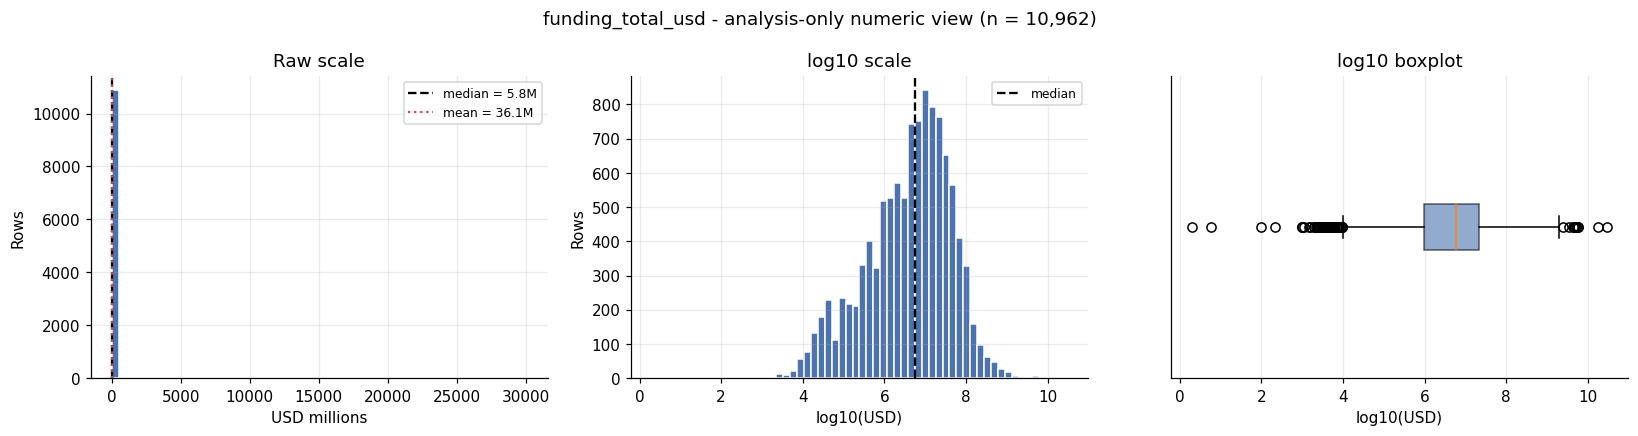

In [15]:
funding_values = funding_usd.dropna()
funding_log = np.log10(funding_values)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(funding_values / 1e6, bins=60, color="#4C72B0", edgecolor="white")
axes[0].axvline(
    funding_values.median() / 1e6,
    color="black",
    linestyle="--",
    label=f"median = {funding_values.median() / 1e6:,.1f}M",
)
axes[0].axvline(
    funding_values.mean() / 1e6,
    color="#C44E52",
    linestyle=":",
    label=f"mean = {funding_values.mean() / 1e6:,.1f}M",
)
axes[0].set_title("Raw scale")
axes[0].set_xlabel("USD millions")
axes[0].set_ylabel("Rows")
axes[0].legend(fontsize=8)

axes[1].hist(funding_log, bins=60, color="#4C72B0", edgecolor="white")
axes[1].axvline(np.log10(funding_values.median()), color="black", linestyle="--", label="median")
axes[1].set_title("log10 scale")
axes[1].set_xlabel("log10(USD)")
axes[1].set_ylabel("Rows")
axes[1].legend(fontsize=8)

axes[2].boxplot(
    funding_log,
    orientation="horizontal",
    patch_artist=True,
    boxprops={"facecolor": "#4C72B0", "alpha": 0.6},
)
axes[2].set_title("log10 boxplot")
axes[2].set_xlabel("log10(USD)")
axes[2].set_yticks([])

fig.suptitle(f"funding_total_usd - analysis-only numeric view (n = {funding_values.size:,})")
plt.tight_layout()
plt.show()


### 11.3 `funding_rounds`

`funding_rounds` is a discrete count with no missing values. It is strongly
right-skewed: most startups have one or two rounds, while a small tail reaches 18.
The IQR is only one round, so the 1.5 x IQR fence flags a non-trivial share of
high counts; those are genuine large financing histories, not data errors. The
median (one round) is a better summary than the mean, which is pulled upward by
the tail. The variable is a forbidden model input, so it is described here only.

There are no zero-round startups: the labelled sample is effectively conditioned
on having at least one recorded funding round. This is a sample-selection caveat,
not a model-input issue.


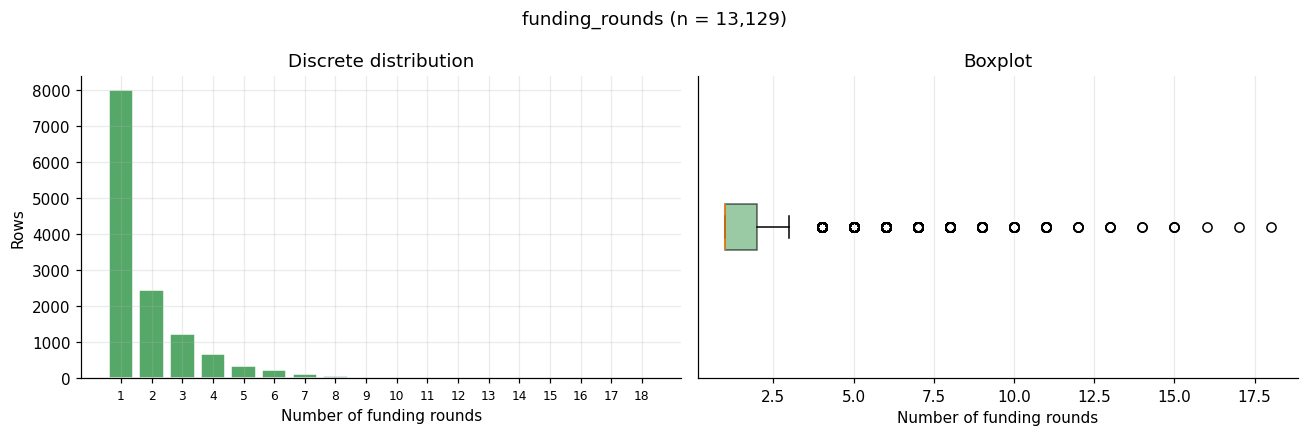

In [16]:
rounds = dataset["funding_rounds"]
round_counts = rounds.value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(round_counts.index, round_counts.values, color="#55A868", edgecolor="white")
axes[0].set_title("Discrete distribution")
axes[0].set_xlabel("Number of funding rounds")
axes[0].set_ylabel("Rows")
axes[0].set_xticks(range(1, int(rounds.max()) + 1))
axes[0].tick_params(axis="x", labelsize=8)

axes[1].boxplot(
    rounds.dropna(),
    orientation="horizontal",
    patch_artist=True,
    boxprops={"facecolor": "#55A868", "alpha": 0.6},
)
axes[1].set_title("Boxplot")
axes[1].set_xlabel("Number of funding rounds")
axes[1].set_yticks([])

fig.suptitle(f"funding_rounds (n = {rounds.notna().sum():,})")
plt.tight_layout()
plt.show()


### 11.4 `founding_year`

`founding_year` is the only numerical model input. It is left-skewed: the mass is
concentrated in the 2000s and early 2010s, with a thin tail of much older firms.
The median is 2007 and the IQR is narrow, so the 1.5 x IQR rule flags old firms as
low outliers. The maximum is 2016 and only one row is dated 2016; no valid founding
date falls between 2017 and 2026, and the latest first-funding date is 2015-12-04.
This is consistent with a data snapshot taken around 2016, not a natural limit of the
variable. More than a quarter of the rows have no usable founding year, so
all statements about this variable apply to the observed subset only; the missing
values are not imputed here.


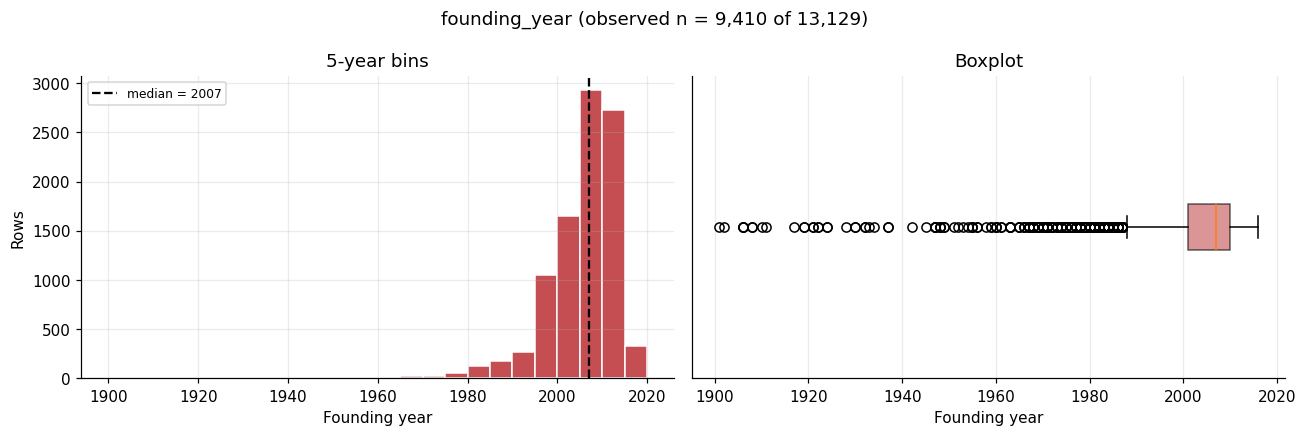

In [17]:
years = dataset["founding_year"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(years, bins=np.arange(1900, 2021, 5), color="#C44E52", edgecolor="white")
axes[0].axvline(years.median(), color="black", linestyle="--", label=f"median = {years.median():.0f}")
axes[0].set_title("5-year bins")
axes[0].set_xlabel("Founding year")
axes[0].set_ylabel("Rows")
axes[0].legend(fontsize=8)

axes[1].boxplot(
    years,
    orientation="horizontal",
    patch_artist=True,
    boxprops={"facecolor": "#C44E52", "alpha": 0.6},
)
axes[1].set_title("Boxplot")
axes[1].set_xlabel("Founding year")
axes[1].set_yticks([])

fig.suptitle(f"founding_year (observed n = {years.size:,} of {len(dataset):,})")
plt.tight_layout()
plt.show()


## 12. Categorical features

Three categorical variables are profiled: `country_code`, `city` and
`primary_category`. For each, the summary reports non-missing count, missingness,
cardinality, top-level concentration and the number/share of rare levels (fewer
than 30 rows). Rare levels are not merged here: the chi-square test in section 17
uses an explicit grouping rule.

**Denominators.** In the categorical summary and top-category tables, all shares
use non-missing rows as the denominator; `missing (%)` is the exception and uses
all 13,129 rows. This is why the top-10 share of `primary_category` here is larger
than the baseline's "of all rows" coverage: both are correct, but the denominators
differ.


In [18]:
def categorical_profile(series, label):
    counts = series.value_counts()
    total = int(counts.sum())
    rare = counts[counts < 30]
    return pd.Series(
        {
            "non-missing": total,
            "missing": int(series.isna().sum()),
            "missing (%)": round(100 * series.isna().mean(), 1),
            "distinct levels": int(series.nunique()),
            "top level": counts.index[0],
            "top count": int(counts.iloc[0]),
            "top share (%)": round(100 * counts.iloc[0] / total, 1),
            "top 5 share (%)": round(100 * counts.head(5).sum() / total, 1),
            "top 10 share (%)": round(100 * counts.head(10).sum() / total, 1),
            "levels <30 rows": int(len(rare)),
            "rows in levels <30 (%)": round(100 * rare.sum() / total, 1),
            "singleton levels": int((counts == 1).sum()),
        },
        name=label,
    )

categorical_profiles = pd.concat(
    [
        categorical_profile(dataset["country_code"], "country_code"),
        categorical_profile(dataset["city"], "city"),
        categorical_profile(dataset["primary_category"], "primary_category"),
    ],
    axis=1,
).T
display(categorical_profiles)


def top_categories(series, n=15):
    counts = series.value_counts()
    total = int(counts.sum())
    table = counts.head(n).to_frame("rows")
    table.index.name = series.name
    table["share of non-missing (%)"] = (100 * table["rows"] / total).round(1)
    table["cumulative (%)"] = table["share of non-missing (%)"].cumsum().round(1)
    return table


def plot_top_categories(series, title, color, n=15, figsize=(9, 5)):
    counts = series.value_counts().head(n).sort_values()
    fig, ax = plt.subplots(figsize=figsize)
    ax.barh(counts.index, counts.values, color=color, edgecolor="white")
    ax.set_title(title)
    ax.set_xlabel("Rows (non-missing)")
    ax.set_ylabel("")
    for position, value in enumerate(counts.values):
        ax.text(value, position, f" {value:,}", va="center", fontsize=8)
    ax.margins(x=0.15)
    plt.tight_layout()
    plt.show()


,non-missing,missing,missing (%),distinct levels,top level,top count,top share (%),top 5 share (%),top 10 share (%),levels <30 rows,rows in levels <30 (%),singleton levels
country_code,11138,1991,15.2,83,USA,8172,73.4,85.0,91.0,62,3.5,21
city,10996,2133,16.2,1671,San Francisco,855,7.8,19.7,27.3,1611,44.5,919
primary_category,12052,1077,8.2,503,Biotechnology,1079,9.0,31.4,44.9,438,20.0,123


### 12.1 `country_code`

`country_code` is concentrated: one country dominates the labelled set, and the
top few levels cover most non-missing rows. The remaining levels are numerous but
individually small, including many singletons. This is a case where grouping rare
countries is likely necessary before any test that assumes adequate expected
counts.


,rows,share of non-missing (%),cumulative (%)
country_code,,,
USA,8172,73.4,73.4
GBR,540,4.8,78.2
CAN,395,3.5,81.7
RUS,183,1.6,83.3
FRA,181,1.6,84.9
DEU,181,1.6,86.5
CHN,180,1.6,88.1
IND,129,1.2,89.3
ESP,94,0.8,90.1


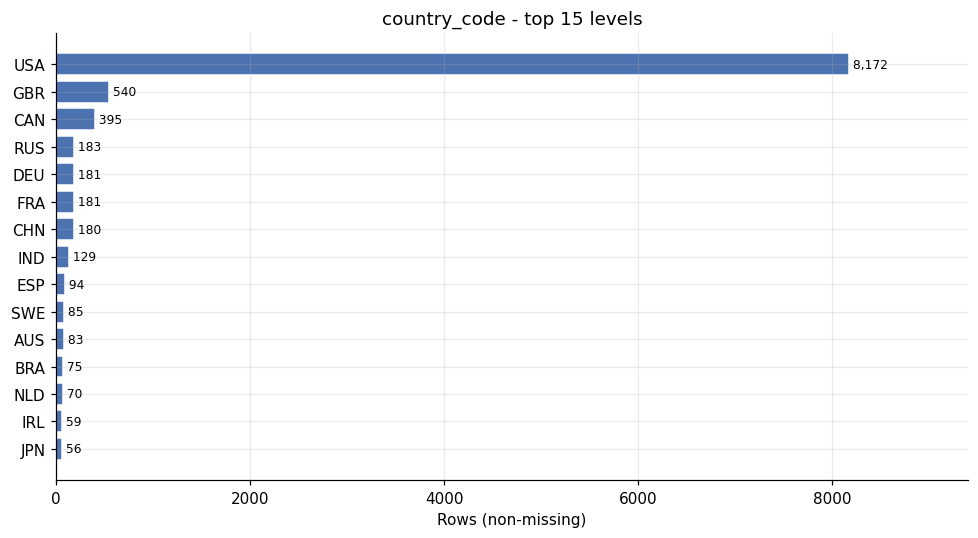

In [19]:
display(top_categories(dataset["country_code"]))
plot_top_categories(
    dataset["country_code"],
    "country_code - top 15 levels",
    "#4C72B0",
)


### 12.2 `city`

`city` is the most fragmented categorical variable: the top cities are well known
startup hubs, but most levels are rare and many appear only once. The top-15 chart
therefore covers only a minority of rows. Any city-level analysis or encoding must
handle this long tail explicitly; the current model pipeline groups rare levels,
and the chi-square test in section 17 uses a similar rule.


,rows,share of non-missing (%),cumulative (%)
city,,,
San Francisco,855,7.8,7.8
New York,646,5.9,13.7
London,258,2.3,16.0
Palo Alto,207,1.9,17.9
Seattle,198,1.8,19.7
Austin,179,1.6,21.3
Mountain View,179,1.6,22.9
Cambridge,164,1.5,24.4
San Diego,158,1.4,25.8


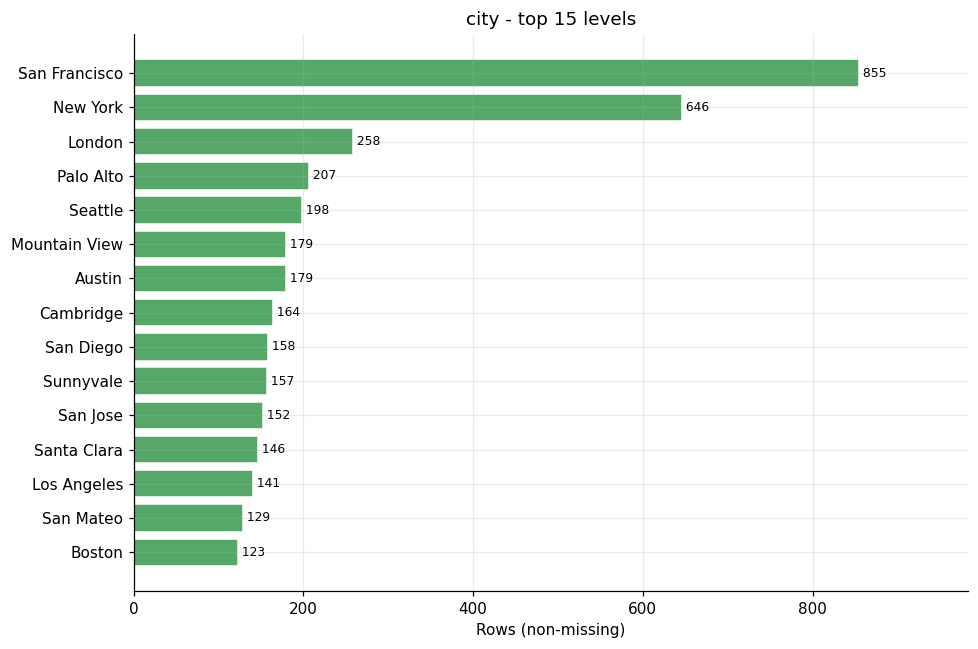

In [20]:
display(top_categories(dataset["city"]))
plot_top_categories(
    dataset["city"],
    "city - top 15 levels",
    "#55A868",
    figsize=(9, 6),
)


### 12.3 `primary_category`

`primary_category` is moderately concentrated: a handful of sectors cover a large
share of rows, but the distribution still has a long tail of small levels. The
baseline audit already reported the cardinality; the table and chart below show
where the mass sits and how much of the data the rare levels represent. This is
the variable planned for the chi-square test, so the rare-level grouping rule is
the key methodological decision.


,rows,share of non-missing (%),cumulative (%)
primary_category,,,
Biotechnology,1079,9.0,9.0
Software,946,7.8,16.8
Curated Web,741,6.1,22.9
Advertising,582,4.8,27.7
E-Commerce,437,3.6,31.3
Mobile,409,3.4,34.7
Enterprise Software,364,3.0,37.7
Games,306,2.5,40.2
Analytics,281,2.3,42.5


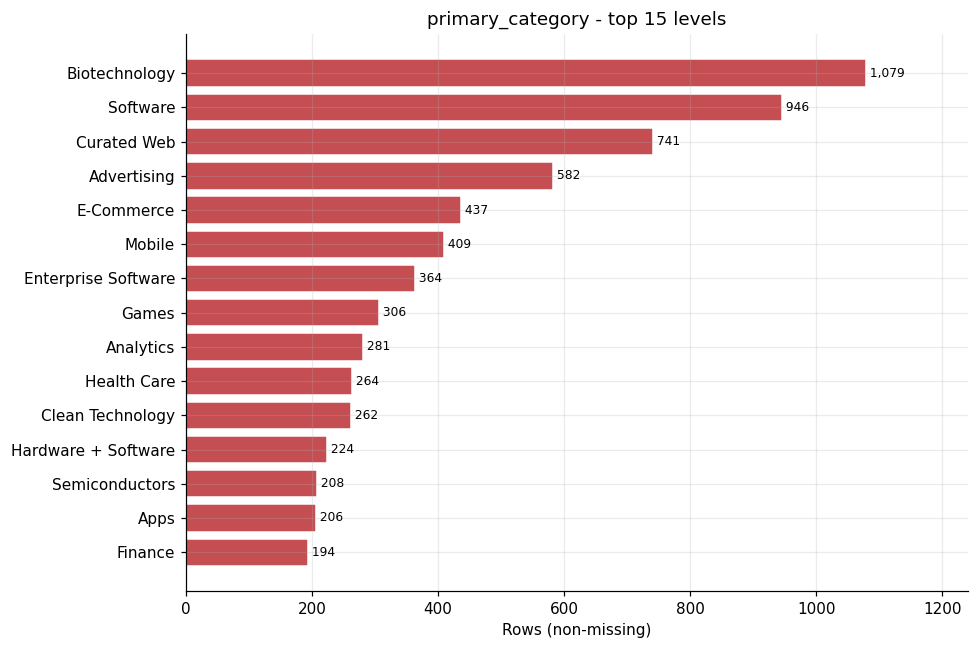

In [21]:
display(top_categories(dataset["primary_category"]))
plot_top_categories(
    dataset["primary_category"],
    "primary_category - top 15 levels",
    "#C44E52",
    figsize=(9, 6),
)


## 13. Key descriptive findings

- **Funding variables are descriptive only.** `funding_total_usd` and
  `funding_rounds` are in `splitting.FORBIDDEN_FEATURES`; they must not be added
  to the model inputs. Their distributions are still useful for understanding the
  sample and for the report.
- **`funding_total_usd` is heavily right-skewed.** The mean is far above the
  median, the tail reaches tens of billions, and the IQR rule flags a substantial
  minority of high values. Median/IQR and a log10 view are the defensible
  summaries; the 2 USD minimum is a data-quality flag.
- **`funding_rounds` is a discrete right-skewed count.** Most startups have one or
  two rounds; the tail is real financing history, not an error. The absence of
  zero-round startups means the sample is conditioned on having at least one
  recorded round.
- **`founding_year` is left-skewed and incomplete.** The sample is concentrated in
  the 2000s, the maximum is the 2016 snapshot boundary, and more than a quarter of
  rows have no usable year. The Mann-Whitney test in section 17 describes the
  observed subset only.
- **Categorical concentration differs sharply.** Country is dominated by one
  level; city is extremely fragmented; primary_category has a moderate head and a
  long rare tail. Rare-level grouping is required for the chi-square test in
  section 17.
- **No preprocessing was performed.** All transformations above are analysis-only;
  `dataset`, the official feature contract and the preprocessing pipeline are
  unchanged.


## 15. Correlation and relationship analysis

Sections 10-13 described each variable in isolation. This section examines how
the requested variables relate to each other and to the binary outcome
`target` (1 = ipo/acquired, 0 = closed).

**Scope and statistical choices**

- `target` is the outcome, never a model input. `funding_total_usd` and
  `funding_rounds` are in `splitting.FORBIDDEN_FEATURES`; they are used here for
  description only and are never added to `X`.
- Correlations are **descriptive**. They quantify monotonic (Spearman) or linear
  (Pearson) association in this sample; they say nothing about causation.
- **Spearman is the default.** `funding_total_usd` is extremely skewed
  (skewness about 59.8), `funding_rounds` is a discrete heavy-tailed count, and
  `founding_year` is bounded and left-skewed. Rank correlation is robust to these
  shapes. Pearson is reported only where its assumptions are defensible
  (section 15.2).
- Correlations use **pairwise complete observations**, so each pair has its own
  sample size. The counts are shown rather than hidden.
- Categorical outcome comparisons use only levels with at least **100 labelled
  rows** and report **95 % Wilson confidence intervals**. Small levels are
  excluded from interpretation, not deleted from the dataset.
- No imputation, encoding, scaling or model training is performed. `log10` is
  used only to make figures readable, never as a stored transformation.


### 15.1 Spearman rank correlation

The matrix and heatmap below report Spearman's rho on pairwise complete rows.
Values near +1 or -1 indicate a strong monotonic association, values near 0
indicate none, and the diagonal is 1 by construction. Each off-diagonal cell
should be read together with its pairwise sample size from the first table.


,pair,n (pairwise complete)
0,funding_total_usd vs funding_rounds,10962
1,funding_total_usd vs founding_year,8012
2,funding_total_usd vs target,10962
3,funding_rounds vs founding_year,9410
4,funding_rounds vs target,13129
5,founding_year vs target,9410


,funding_total_usd,funding_rounds,founding_year,target
funding_total_usd,1.000,0.495,-0.567,0.457
funding_rounds,0.495,1.000,-0.163,0.328
founding_year,-0.567,-0.163,1.000,-0.399
target,0.457,0.328,-0.399,1.000


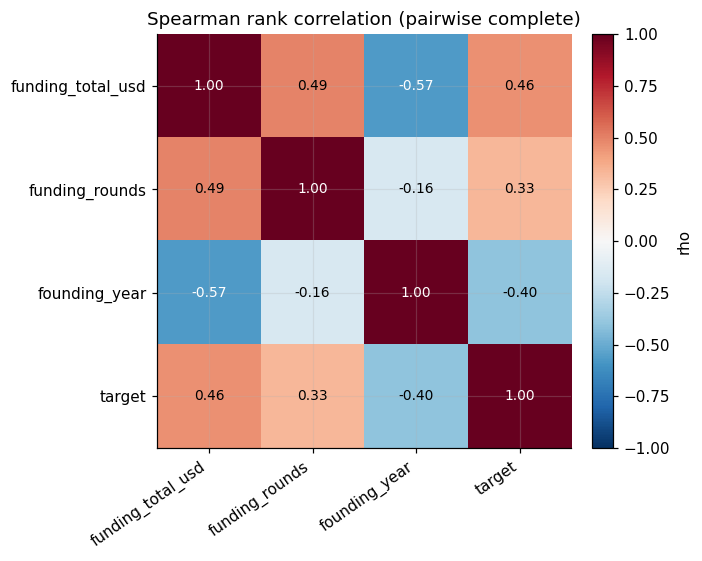

In [22]:
relationship_frame = pd.DataFrame(
    {
        "funding_total_usd": funding_usd,
        "funding_rounds": dataset["funding_rounds"],
        "founding_year": dataset["founding_year"],
        "target": dataset["target"],
    }
)

pair_counts = pd.DataFrame(
    [
        {
            "pair": f"{left} vs {right}",
            "n (pairwise complete)": int(relationship_frame[[left, right]].dropna().shape[0]),
        }
        for position, left in enumerate(relationship_frame.columns)
        for right in relationship_frame.columns[position + 1 :]
    ]
)
display(pair_counts)

spearman_matrix = relationship_frame.corr(method="spearman")
display(spearman_matrix.round(3))

fig, ax = plt.subplots(figsize=(6.5, 5.2))
image = ax.imshow(spearman_matrix.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(spearman_matrix)))
ax.set_xticklabels(spearman_matrix.columns, rotation=35, ha="right")
ax.set_yticks(range(len(spearman_matrix)))
ax.set_yticklabels(spearman_matrix.index)
for row in range(len(spearman_matrix)):
    for column in range(len(spearman_matrix)):
        value = spearman_matrix.values[row, column]
        ax.text(
            column,
            row,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=9,
            color="white" if abs(value) > 0.5 else "black",
        )
ax.set_title("Spearman rank correlation (pairwise complete)")
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04, label="rho")
plt.tight_layout()
plt.show()


### 15.2 Pearson correlation only where its assumptions hold

Pearson measures **linear** association and is sensitive to outliers and
leverage. In this dataset the only pair where it is defensible is
`target` vs `founding_year`: the outcome is binary and the year is bounded, so
the correlation is the usual point-biserial correlation, computed on the 9,410
rows that have an observed year. It is still reported descriptively, because
`founding_year` is left-skewed and the linearity assumption is approximate.

Pearson is **not** interpreted for the funding variables. `funding_total_usd`
has skewness about 59.8 and a maximum near 30 billion USD, so Pearson is
dominated by a handful of extreme values: it gives about 0.06 against a
Spearman rho of about 0.46 for the same pair. `funding_rounds` is a discrete
count with heavy ties and a long right tail. The table below shows Pearson and
Spearman side by side as a **method check**; only the `target` vs
`founding_year` Pearson value is interpreted.


In [23]:
def correlation_pair(left, right):
    pair = pd.DataFrame({"left": left, "right": right}).dropna()
    return {
        "pair": f"{left.name} vs {right.name}",
        "n": int(len(pair)),
        "pearson": pair["left"].corr(pair["right"], method="pearson"),
        "spearman": pair["left"].corr(pair["right"], method="spearman"),
    }


pearson_check = pd.DataFrame(
    [
        correlation_pair(dataset["target"], dataset["founding_year"]),
        correlation_pair(dataset["target"], dataset["funding_rounds"]),
        correlation_pair(dataset["target"], funding_usd),
        correlation_pair(dataset["funding_rounds"], funding_usd),
    ]
)
pearson_check["pearson interpreted"] = [
    "yes - point-biserial",
    "no - discrete, heavy ties",
    "no - extreme skew and leverage",
    "no - extreme skew and leverage",
]
display(pearson_check.round(3))

pearson_year = dataset["founding_year"].corr(dataset["target"], method="pearson")
print(
    f"Pearson r(target, founding_year) = {pearson_year:.3f} "
    f"on {int(dataset[['founding_year', 'target']].dropna().shape[0]):,} observed rows."
)


,pair,n,pearson,spearman,pearson interpreted
0,target vs founding_year,9410,-0.299,-0.399,yes - point-biserial
1,target vs funding_rounds,13129,0.286,0.328,"no - discrete, heavy ties"
2,target vs funding_total_usd,10962,0.060,0.457,no - extreme skew and leverage
3,funding_rounds vs funding_total_usd,10962,0.085,0.495,no - extreme skew and leverage


Pearson r(target, founding_year) = -0.299 on 9,410 observed rows.


### 15.3 Pairwise numerical relationships

The scatter plots below show the shape behind the correlation matrix. `log10` is
applied to funding only for readability, and a small random jitter is added to
the discrete counts so that overplotting does not hide density. Neither is a
stored transformation.

The rank correlations are consistent across the panels: funding rises with the
number of rounds (rho about 0.49), funding is higher for older firms (rho about
-0.57 with `founding_year`), and rounds have a weaker negative association with
founding year (rho about -0.16). Colouring by `target` also shows that successes
concentrate in the higher-funding and higher-round region, but the groups overlap
heavily. These are sample associations, not causal effects.


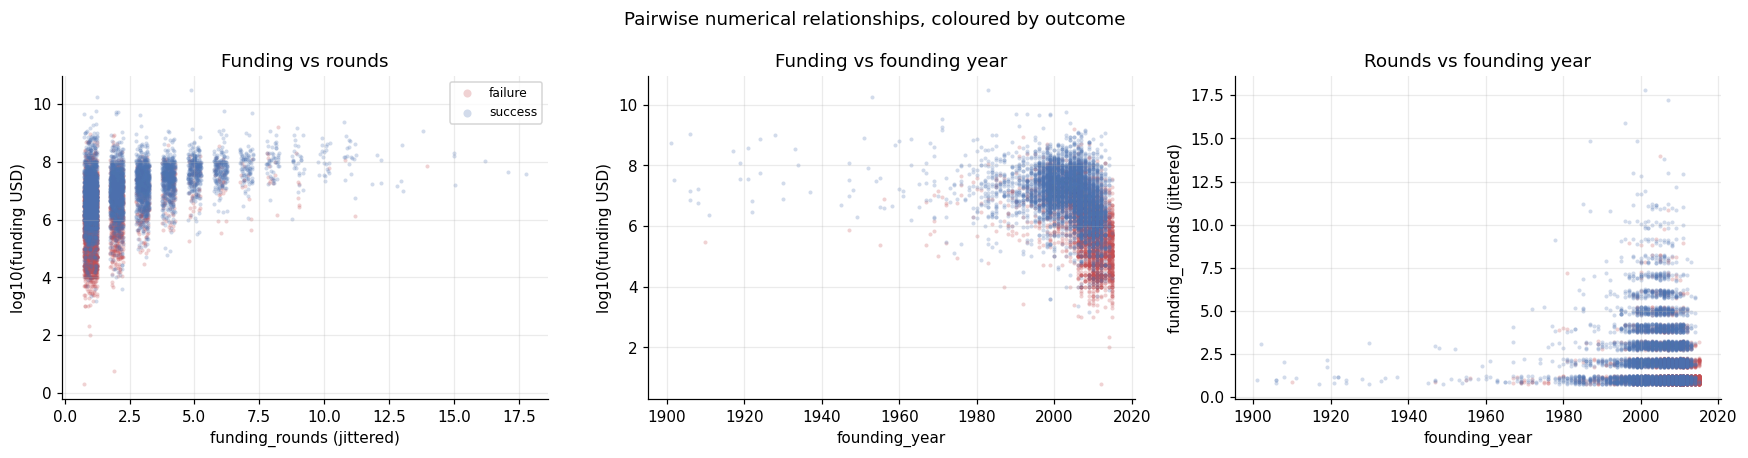

In [24]:
pairwise_frame = relationship_frame.dropna(subset=["funding_total_usd"])
rng = np.random.default_rng(0)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for outcome, color, label in ((0, "#C44E52", "failure"), (1, "#4C72B0", "success")):
    subset = pairwise_frame[pairwise_frame["target"] == outcome]
    axes[0].scatter(
        subset["funding_rounds"] + rng.uniform(-0.25, 0.25, len(subset)),
        np.log10(subset["funding_total_usd"]),
        s=7,
        alpha=0.25,
        color=color,
        label=label,
        linewidths=0,
    )
    axes[1].scatter(
        subset["founding_year"],
        np.log10(subset["funding_total_usd"]),
        s=7,
        alpha=0.25,
        color=color,
        label=label,
        linewidths=0,
    )
    axes[2].scatter(
        subset["founding_year"],
        subset["funding_rounds"] + rng.uniform(-0.25, 0.25, len(subset)),
        s=7,
        alpha=0.25,
        color=color,
        label=label,
        linewidths=0,
    )

axes[0].set(
    xlabel="funding_rounds (jittered)",
    ylabel="log10(funding USD)",
    title="Funding vs rounds",
)
axes[1].set(
    xlabel="founding_year",
    ylabel="log10(funding USD)",
    title="Funding vs founding year",
)
axes[2].set(
    xlabel="founding_year",
    ylabel="funding_rounds (jittered)",
    title="Rounds vs founding year",
)
axes[0].legend(fontsize=8, markerscale=2)
fig.suptitle("Pairwise numerical relationships, coloured by outcome")
plt.tight_layout()
plt.show()


### 15.4 Categorical outcomes: country

`country_code` has 83 levels, but only **8** have at least 100 labelled rows;
those 8 cover **89.4 %** of non-missing country rows. The table and the figure
therefore describe the well-populated countries only. The dashed line is the
overall success rate (53.1 %), and the error bars are 95 % Wilson intervals.

The spread is large: USA 64.4 % (CI 63.4-65.5), Canada 60.0 %, China 63.3 %,
Germany 57.5 %, versus Russia 7.7 % (CI 4.6-12.4, n = 183) and the United Kingdom
48.0 %. Overlapping intervals mean that most pairwise differences are not
established by this descriptive view; no formal country-level test is part of
this deliverable. Country is a proxy for many unmeasured factors (ecosystem,
sector mix, sample composition), so no causal reading is justified. The low
Russian rate is a signal for follow-up, not a conclusion.


,count,successes,success_rate (%),CI low (%),CI high (%)
category,,,,,
USA,8172,5265,64.4,63.4,65.5
GBR,540,259,48.0,43.8,52.2
CAN,395,237,60.0,55.1,64.7
RUS,183,14,7.7,4.6,12.4
DEU,181,104,57.5,50.2,64.4
FRA,181,90,49.7,42.5,56.9
CHN,180,114,63.3,56.1,70.0
IND,129,60,46.5,38.1,55.1


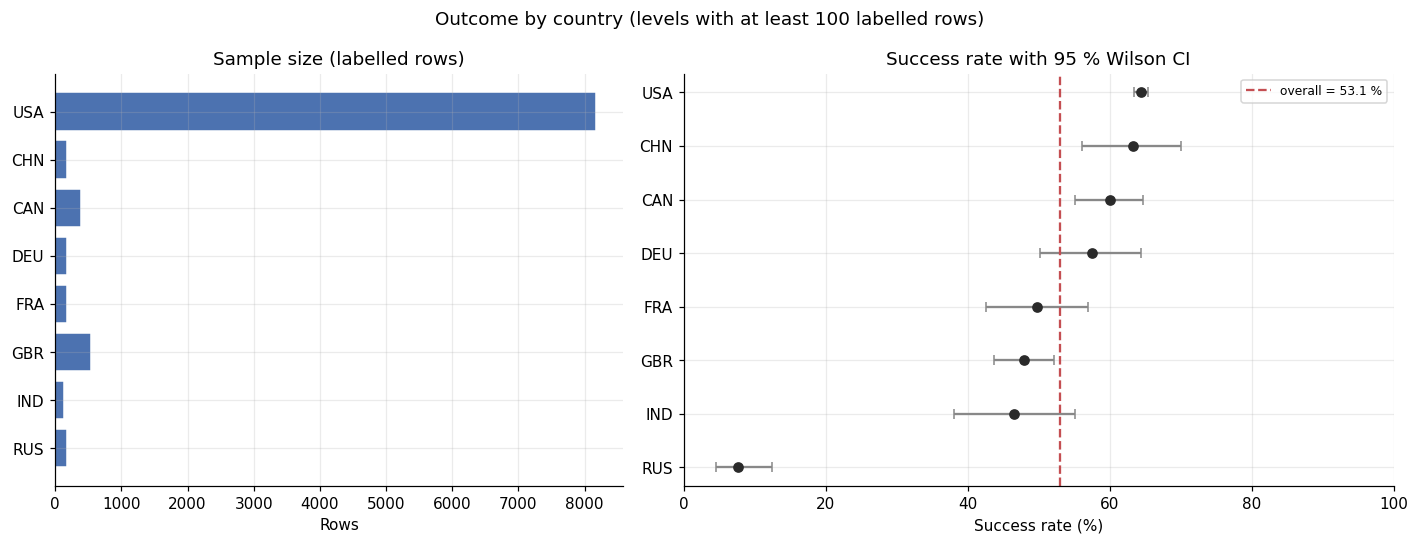

In [25]:
def wilson_interval(successes, total, z=1.96):
    proportion = successes / total
    denominator = 1 + z * z / total
    centre = (proportion + z * z / (2 * total)) / denominator
    half_width = (
        z
        * np.sqrt(proportion * (1 - proportion) / total + z * z / (4 * total * total))
        / denominator
    )
    return centre - half_width, centre + half_width


def outcome_by_category(series, target, min_rows=100):
    frame = pd.DataFrame({"category": series, "target": target}).dropna(
        subset=["category"]
    )
    grouped = frame.groupby("category", observed=True)["target"].agg(
        count="count", successes="sum"
    )
    grouped = grouped[grouped["count"] >= min_rows].sort_values(
        "count", ascending=False
    )
    grouped["success_rate (%)"] = 100 * grouped["successes"] / grouped["count"]
    low, high = wilson_interval(
        grouped["successes"].to_numpy(), grouped["count"].to_numpy()
    )
    grouped["CI low (%)"] = 100 * low
    grouped["CI high (%)"] = 100 * high
    return grouped


def plot_outcome_by_category(table, title, figsize=(13, 5)):
    ordered = table.sort_values("success_rate (%)")
    fig, axes = plt.subplots(
        1, 2, figsize=figsize, gridspec_kw={"width_ratios": [1, 1.25]}
    )
    axes[0].barh(ordered.index, ordered["count"], color="#4C72B0", edgecolor="white")
    axes[0].set_title("Sample size (labelled rows)")
    axes[0].set_xlabel("Rows")
    axes[0].set_ylabel("")
    axes[1].errorbar(
        ordered["success_rate (%)"],
        ordered.index,
        xerr=[
            ordered["success_rate (%)"] - ordered["CI low (%)"],
            ordered["CI high (%)"] - ordered["success_rate (%)"],
        ],
        fmt="o",
        color="#2A2A2A",
        ecolor="#888888",
        capsize=3,
        markersize=6,
    )
    axes[1].axvline(
        100 * dataset["target"].mean(),
        color="#C44E52",
        linestyle="--",
        label=f"overall = {100 * dataset['target'].mean():.1f} %",
    )
    axes[1].set_xlim(0, 100)
    axes[1].set_xlabel("Success rate (%)")
    axes[1].set_ylabel("")
    axes[1].set_title("Success rate with 95 % Wilson CI")
    axes[1].legend(fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


country_outcomes = outcome_by_category(
    dataset["country_code"], dataset["target"], min_rows=100
)
display(country_outcomes.round(1))
plot_outcome_by_category(
    country_outcomes,
    "Outcome by country (levels with at least 100 labelled rows)",
)


### 15.5 Categorical outcomes: primary_category

`primary_category` has 503 levels. **26** have at least 100 labelled rows and
cover **64.6 %** of non-missing category rows. The table and figure show the top
15 by sample size; all of them have at least 194 rows, so the small-sample
caution is satisfied for what is displayed.

Success rates among these 15 levels range from about 34 % (Apps, n = 206) to
about 77 % (Enterprise Software, n = 364). Biotechnology (75.4 %), Semiconductors
(75.0 %) and Analytics (73.7 %) sit at the high end, while Curated Web (44.9 %)
and Games (48.4 %) sit below the overall rate. The 95 % Wilson intervals are
shown because they make the uncertainty visible: differences of a few points are
not established by this descriptive view.

The category is a coarse sector label derived from `category_list`. It may proxy
for business model, capital intensity and sample composition, so these
differences must not be read causally. The rare-level grouping rule needed for
the chi-square test is still an open decision.


,count,successes,success_rate (%),CI low (%),CI high (%)
category,,,,,
Biotechnology,1079,814,75.4,72.8,77.9
Software,946,610,64.5,61.4,67.5
Curated Web,741,333,44.9,41.4,48.5
Advertising,582,358,61.5,57.5,65.4
E-Commerce,437,216,49.4,44.8,54.1
Mobile,409,247,60.4,55.6,65.0
Enterprise Software,364,280,76.9,72.3,81.0
Games,306,148,48.4,42.8,54.0
Analytics,281,207,73.7,68.2,78.5


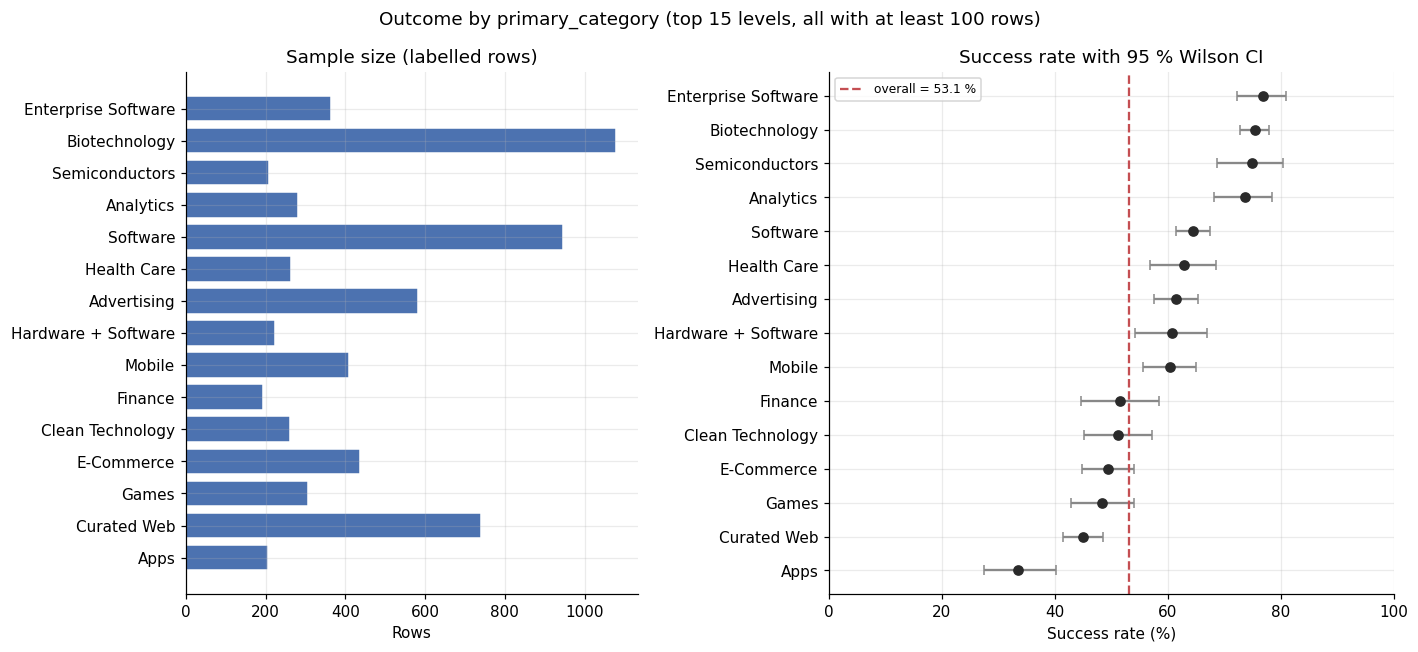

In [26]:
category_outcomes = outcome_by_category(
    dataset["primary_category"], dataset["target"], min_rows=100
).head(15)
display(category_outcomes.round(1))
plot_outcome_by_category(
    category_outcomes,
    "Outcome by primary_category (top 15 levels, all with at least 100 rows)",
    figsize=(13, 6),
)


### 15.6 Funding and outcome

This comparison uses the analysis-only `funding_usd` Series built in section
10.1 (`"-"` set to missing, then numeric parsing). `dataset["funding_total_usd"]`
is unchanged, and the variable remains a **forbidden model input**; this is a
descriptive view, not a feature-engineering step.

Only observed funding values are used. Missingness differs by outcome: 1,310
failures (21.3 % of failures) and 857 successes (12.3 % of successes) have no
numeric funding. The median is about **12.5 M USD for successes** versus
**1.24 M USD for failures**, roughly a **10x** gap; the IQR is 3.6-36.1 M for
successes versus 0.2-7.0 M for failures. The means (56.2 M vs 10.9 M) are
tail-dominated and are reported only for completeness.

The distributions still overlap substantially: many failed startups raised large
amounts, and many successful ones raised little. Funding is also measured over
the life of the company, so it is not a pre-outcome predictor in this protocol.
The figure uses `log10` only to make both bodies visible. The formal Mann-Whitney
test is performed in section 17.


,outcome,n observed,missing,median,Q1,Q3,mean
0,failure,4851,1310,"1,240,000.00","200,000.00","7,000,000.00","10,946,028.84"
1,success,6111,857,"12,500,000.00","3,600,000.00","36,136,257.00","56,152,157.12"


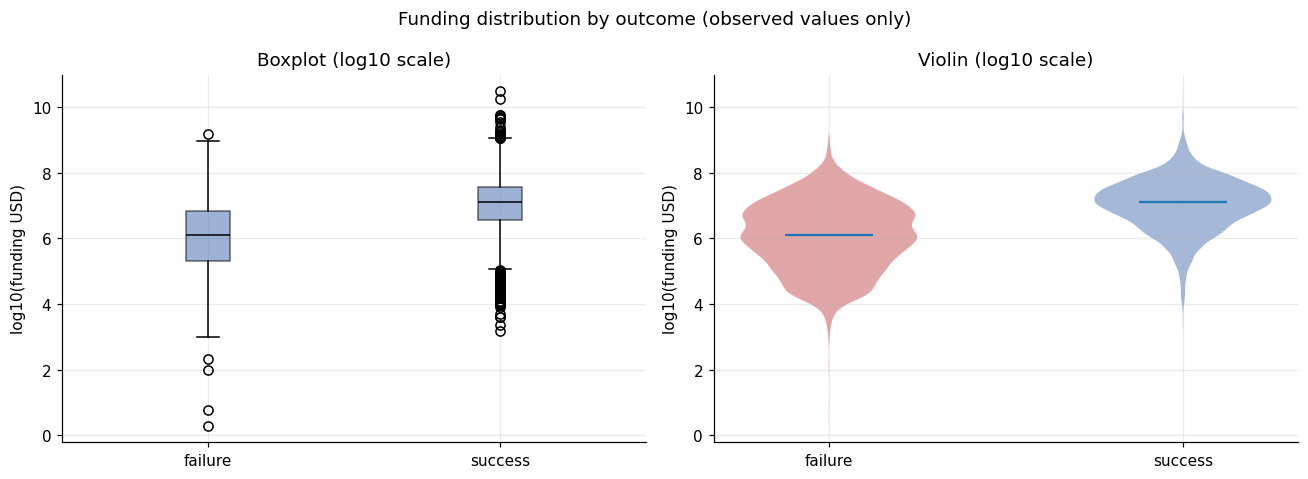

In [27]:
def outcome_group_summary(series, target):
    rows = []
    for outcome, label in ((0, "failure"), (1, "success")):
        values = series[target == outcome].dropna()
        q1, q3 = values.quantile([0.25, 0.75])
        rows.append(
            {
                "outcome": label,
                "n observed": int(len(values)),
                "missing": int((target == outcome).sum() - len(values)),
                "median": values.median(),
                "Q1": q1,
                "Q3": q3,
                "mean": values.mean(),
            }
        )
    return pd.DataFrame(rows)


funding_by_outcome = outcome_group_summary(funding_usd, dataset["target"])
with pd.option_context("display.float_format", lambda value: f"{value:,.2f}"):
    display(funding_by_outcome)

funding_failure = np.log10(funding_usd[dataset["target"] == 0].dropna())
funding_success = np.log10(funding_usd[dataset["target"] == 1].dropna())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
axes[0].boxplot(
    [funding_failure, funding_success],
    tick_labels=["failure", "success"],
    patch_artist=True,
    boxprops={"facecolor": "#4C72B0", "alpha": 0.55},
    medianprops={"color": "black"},
)
axes[0].set_ylabel("log10(funding USD)")
axes[0].set_title("Boxplot (log10 scale)")

violins = axes[1].violinplot(
    [funding_failure, funding_success], showmedians=True, showextrema=False
)
for body, color in zip(violins["bodies"], ["#C44E52", "#4C72B0"]):
    body.set_facecolor(color)
    body.set_alpha(0.5)
axes[1].set_xticks([1, 2])
axes[1].set_xticklabels(["failure", "success"])
axes[1].set_ylabel("log10(funding USD)")
axes[1].set_title("Violin (log10 scale)")

fig.suptitle("Funding distribution by outcome (observed values only)")
plt.tight_layout()
plt.show()


### 15.7 Founding year and outcome

This comparison uses only the 9,410 rows with an observed `founding_year`.
Missingness is **not** balanced across outcomes: 2,143 failures (34.8 %) and
1,576 successes (22.6 %) have no usable year. Any comparison is therefore
conditional on having an observed year, and the missing values are not imputed.

Among observed years, successes are older: median **2004** (IQR 1999-2009)
versus **2009** (IQR 2006-2012) for failures. The overlaid histograms and the
boxplot show the shift. This is consistent with an **observation-window** effect:
acquisitions and IPOs take time, while closures can happen sooner, and firms
founded close to the 2016 snapshot have had less time to reach an exit. The
target also pools ipo and acquired into class 1 and closed into class 0, so the
contrast is about exit type, not a direct measure of intrinsic quality.

The differential missingness and the historical window are the two main reasons
not to read this as a causal effect. The formal Mann-Whitney test is performed in
section 17.


,outcome,labelled rows,observed year,missing year,missing share (%)
0,failure,6161,4018,2143,34.8
1,success,6968,5392,1576,22.6


,outcome,n observed,missing,median,Q1,Q3,mean
0,failure,4018,2143,"2,009.0","2,006.0","2,012.0","2,008.0"
1,success,5392,1576,"2,004.0","1,999.0","2,009.0","2,002.4"


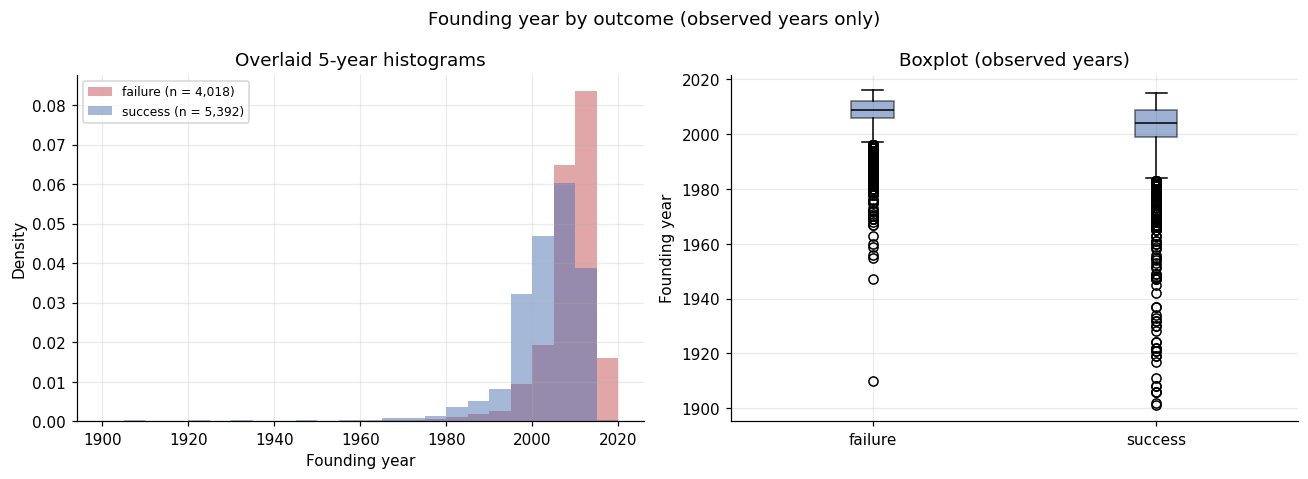

In [28]:
year_missing_by_outcome = pd.DataFrame(
    [
        {
            "outcome": label,
            "labelled rows": int((dataset["target"] == outcome).sum()),
            "observed year": int(
                dataset.loc[dataset["target"] == outcome, "founding_year"].notna().sum()
            ),
            "missing year": int(
                dataset.loc[dataset["target"] == outcome, "founding_year"].isna().sum()
            ),
            "missing share (%)": round(
                100
                * dataset.loc[dataset["target"] == outcome, "founding_year"]
                .isna()
                .mean(),
                1,
            ),
        }
        for outcome, label in ((0, "failure"), (1, "success"))
    ]
)
display(year_missing_by_outcome)

year_by_outcome = outcome_group_summary(dataset["founding_year"], dataset["target"])
with pd.option_context("display.float_format", lambda value: f"{value:,.1f}"):
    display(year_by_outcome)

year_failure = dataset.loc[dataset["target"] == 0, "founding_year"].dropna()
year_success = dataset.loc[dataset["target"] == 1, "founding_year"].dropna()
bins = np.arange(1900, 2021, 5)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for values, color, label in (
    (year_failure, "#C44E52", "failure"),
    (year_success, "#4C72B0", "success"),
):
    axes[0].hist(
        values,
        bins=bins,
        alpha=0.5,
        color=color,
        density=True,
        label=f"{label} (n = {len(values):,})",
    )
axes[0].set(
    xlabel="Founding year",
    ylabel="Density",
    title="Overlaid 5-year histograms",
)
axes[0].legend(fontsize=8)

axes[1].boxplot(
    [year_failure, year_success],
    tick_labels=["failure", "success"],
    patch_artist=True,
    boxprops={"facecolor": "#4C72B0", "alpha": 0.55},
    medianprops={"color": "black"},
)
axes[1].set_ylabel("Founding year")
axes[1].set_title("Boxplot (observed years)")

fig.suptitle("Founding year by outcome (observed years only)")
plt.tight_layout()
plt.show()


## 16. Correlation findings and limitations

**Main descriptive findings**

- **Funding is the strongest numerical associate of the outcome**, but only on
  the rank scale: Spearman rho is about **0.46** for `funding_total_usd` and
  **0.33** for `funding_rounds`. Pearson would understate the first relationship
  (about **0.06**) because of extreme skew and leverage, which is why it is not
  interpreted for funding.
- **Founding year is negatively associated with the outcome**: Spearman rho
  about **-0.40**, and the point-biserial Pearson correlation is about **-0.30**
  on 9,410 observed rows. Successes are older (median 2004 vs 2009).
- **The numerical variables are themselves associated**: funding and rounds
  (rho about **0.49**), funding and founding year (rho about **-0.57**), rounds
  and founding year (rho about **-0.16**). These associations are part of why a
  single bivariate coefficient cannot be read as an isolated effect.
- **Categorical outcomes differ substantially across well-populated levels**:
  country success rates range from 7.7 % (Russia, n = 183) to 64.4 % (USA,
  n = 8,172); among the top-15 categories they range from about 34 % (Apps,
  n = 206) to about 77 % (Enterprise Software, n = 364). The Wilson intervals
  show that many of these differences are uncertain; the corresponding formal
  tests are performed in section 17.
- **Funding differs by outcome**: median 12.5 M USD for successes versus 1.24 M
  USD for failures (about 10x), with heavy overlap and 16.5 % missing funding
  overall.

**Limitations**

- Correlation is not causation. Country, category and founding year are
  correlated with many unmeasured factors (ecosystem, sector mix, capital
  intensity, cohort effects).
- Each correlation uses pairwise complete rows, so the sample sizes differ
  (for example 8,012 rows for funding vs founding year, 10,962 for funding vs
  target). The matrix is not based on one common complete-case sample.
- Categorical comparisons exclude levels below 100 labelled rows from
  interpretation. That avoids small-sample noise but also means the displayed
  levels are not a random subset of all categories.
- Missingness is substantial and outcome-related for `founding_year`
  (34.8 % of failures vs 22.6 % of successes) and for funding (21.3 % vs 12.3 %).
  The observed-value comparisons may be biased, and nothing is imputed here.
- The data are a snapshot around 2016. Firms founded near the snapshot have had
  less time to exit, and the target pools ipo and acquired into class 1 while
  class 0 is closed. The `operating` rows are excluded by `prepare_target`.
- `funding_total_usd` and `funding_rounds` are forbidden model inputs. Their
  strong association with the outcome is a leakage warning, not a modelling
  opportunity in this protocol.
- No formal hypothesis test, effect size or multiple-testing correction is
  applied in this section; they are performed in section 17.


## 17. Formal statistical inference

Sections 10-15 described and quantified associations. This section moves to
formal tests for the three primary questions:

1. Is `primary_category` associated with `target`? (chi-square test)
2. Does `founding_year` differ between success and failure? (Mann-Whitney U)
3. Does `funding_total_usd` differ between success and failure? (Mann-Whitney U)

**Rules applied throughout**

- Missing values are handled by **complete-case analysis per test**. Nothing is
  imputed, encoded or scaled, and no model is trained.
- `funding_total_usd` and `funding_rounds` remain **forbidden model inputs**;
  they are tested here for description only, not added to `X`.
- Every test is **two-sided** and reported with its sample sizes, statistic,
  p-value and an effect size.
- The three primary tests form one family and are corrected together with
  Holm's method in section 17.4.
- Statistical significance is not practical importance, and none of these tests
  identifies a causal effect.


### 17.1 Chi-square test: `primary_category` vs `target`

**Hypotheses.** H0: `primary_category` and `target` are independent. H1: they are
associated.

**Rare-category grouping rule.** The raw column has 503 levels, many with a
handful of rows. The primary test collapses every level with **fewer than 30
labelled rows** into a single `"Other"` level. This threshold is not arbitrary:

- it is the rare-level definition already used in section 12, so the analysis is
  consistent with the descriptive work;
- it guarantees that every expected cell count is well above the usual
  Cochran rule of 5 (the minimum is checked below);
- it keeps 65 interpretable levels instead of hundreds of unstable ones.

The `"Other"` level is a heterogeneous residual and is never interpreted as a
real sector. Grouping is a researcher choice, so section 17.2 repeats the test
with a different threshold.

**Assumptions and effect size.** The chi-square test assumes independent
observations and adequate expected counts. Cramér's V is
`sqrt(chi2 / (n * (min(rows, columns) - 1)))`, which reduces to
`sqrt(chi2 / n)` for a 2 x k table. It ranges from 0 (no association) to 1.
As a rough benchmark, 0.1 is small, 0.3 moderate and 0.5 large, but the
benchmark is context-dependent.


In [29]:
from scipy.stats import chi2_contingency


def group_rare_categories(series, min_rows):
    counts = series.value_counts()
    keep = counts[counts >= min_rows].index
    return series.mask(series.notna() & ~series.isin(keep), "Other")


def chi_square_report(series, target, min_rows):
    grouped = group_rare_categories(series, min_rows)
    frame = pd.DataFrame({"category": grouped, "target": target}).dropna(
        subset=["category"]
    )
    table = pd.crosstab(frame["category"], frame["target"])
    chi2, p_value, dof, expected = chi2_contingency(table, correction=False)
    n = int(table.values.sum())
    cramers_v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
    residuals = (table.values - expected) / np.sqrt(expected)
    success_column = list(table.columns).index(1)
    residual_series = pd.Series(residuals[:, success_column], index=table.index)
    summary = pd.DataFrame(
        [
            {"metric": "rows used (n)", "value": f"{n:,}"},
            {"metric": "categories after grouping", "value": f"{table.shape[0]:,}"},
            {
                "metric": "rows collapsed into 'Other'",
                "value": f"{int((grouped == 'Other').sum()):,}",
            },
            {"metric": "chi-square statistic", "value": f"{chi2:,.3f}"},
            {"metric": "degrees of freedom", "value": f"{dof:,}"},
            {"metric": "p-value", "value": f"{p_value:.3e}"},
            {"metric": "Cramer's V", "value": f"{cramers_v:.4f}"},
            {"metric": "minimum expected count", "value": f"{expected.min():,.2f}"},
            {"metric": "cells with expected < 5", "value": f"{int((expected < 5).sum()):,}"},
            {"metric": "cells with expected < 1", "value": f"{int((expected < 1).sum()):,}"},
        ]
    )
    return {
        "summary": summary,
        "table": table,
        "expected": expected,
        "residuals": residual_series.sort_values(key=np.abs, ascending=False),
        "chi2": chi2,
        "p": p_value,
        "dof": dof,
        "v": cramers_v,
        "n": n,
    }


primary_chi = chi_square_report(
    dataset["primary_category"], dataset["target"], min_rows=30
)
display(primary_chi["summary"])
print("Top 10 categories by absolute Pearson residual (success column):")
display(primary_chi["residuals"].head(10).round(2).to_frame("Pearson residual"))


,metric,value
0,rows used (n),"12,052"
1,categories after grouping,66
2,rows collapsed into 'Other',"2,415"
3,chi-square statistic,715.992
4,degrees of freedom,65
5,p-value,2.215e-110
6,Cramer's V,0.2437
7,minimum expected count,12.99
8,cells with expected < 5,0
9,cells with expected < 1,0


Top 10 categories by absolute Pearson residual (success column):


,Pearson residual
category,
Biotechnology,8.17
Enterprise Software,5.12
Other,-4.83
Apps,-4.42
Curated Web,-4.26
Analytics,3.77
Semiconductors,3.50
Application Platforms,-3.37
Software,3.17


### 17.2 Sensitivity analysis: alternative grouping threshold

The grouping rule is a judgement call, so the test is repeated with a stricter
threshold: levels with **fewer than 100 labelled rows** are collapsed into
`"Other"`. This leaves 26 interpretable levels and a larger residual group.
Different degrees of freedom make the raw chi-square statistics not directly
comparable, so the comparison focuses on the p-value, Cramér's V and the
expected-count check. If the conclusion were driven by the threshold, Cramér's V
or the p-value would change materially.


In [30]:
sensitivity_chi = chi_square_report(
    dataset["primary_category"], dataset["target"], min_rows=100
)

sensitivity_comparison = pd.DataFrame(
    [
        {
            "grouping rule": "levels with <30 rows -> Other",
            "n": primary_chi["n"],
            "categories": primary_chi["table"].shape[0],
            "chi-square": primary_chi["chi2"],
            "df": primary_chi["dof"],
            "p-value": primary_chi["p"],
            "Cramer's V": primary_chi["v"],
            "min expected": primary_chi["expected"].min(),
        },
        {
            "grouping rule": "levels with <100 rows -> Other",
            "n": sensitivity_chi["n"],
            "categories": sensitivity_chi["table"].shape[0],
            "chi-square": sensitivity_chi["chi2"],
            "df": sensitivity_chi["dof"],
            "p-value": sensitivity_chi["p"],
            "Cramer's V": sensitivity_chi["v"],
            "min expected": sensitivity_chi["expected"].min(),
        },
    ]
)
sensitivity_display = sensitivity_comparison.copy()
sensitivity_display["p-value"] = sensitivity_display["p-value"].map(
    lambda value: f"{value:.3e}"
)
display(
    sensitivity_display.round(
        {"chi-square": 3, "Cramer's V": 4, "min expected": 2}
    )
)
print(
    f"Primary Cramer's V = {primary_chi['v']:.3f}; "
    f"sensitivity Cramer's V = {sensitivity_chi['v']:.3f}. "
    "Both p-values are far below 1e-100."
)


,grouping rule,n,categories,chi-square,df,p-value,Cramer's V,min expected
0,levels with <30 rows -> Other,12052,66,715.992,65,2.215e-110,0.2437,12.99
1,levels with <100 rows -> Other,12052,27,604.159,26,8.078e-111,0.2239,43.29


Primary Cramer's V = 0.244; sensitivity Cramer's V = 0.224. Both p-values are far below 1e-100.


### 17.3 Mann-Whitney U tests

**Why this test.** The Mann-Whitney U test compares two independent groups
without a normality assumption. It is appropriate here because funding is
extremely skewed with heavy outliers and `founding_year` is bounded and
discrete. The null hypothesis is stochastic equality of the two outcome groups;
the alternative is two-sided.

**Missing values.** Each test uses only the rows where the variable is observed,
separately for successes and failures. Missing counts are reported in the table;
nothing is imputed. The two tests therefore use different subsets of the labelled
sample, and their results are conditional on being observed.

**Effect size.** The rank-biserial correlation is
`r = 2U / (n_success * n_failure) - 1`, where `U` is computed with the success
group as the first sample. Positive values mean successes tend to have larger
values; negative values mean successes tend to have smaller values. The
probability of superiority `U / (n_success * n_failure)` is also reported: it is
the chance that a randomly chosen success exceeds a randomly chosen failure
(ties count as half). Ties are handled by the asymptotic normal approximation
with the usual tie correction.


In [31]:
from scipy.stats import mannwhitneyu


def mann_whitney_report(success_values, failure_values, label):
    success = success_values.dropna()
    failure = failure_values.dropna()
    n_success, n_failure = len(success), len(failure)
    u_statistic, p_value = mannwhitneyu(
        success, failure, alternative="two-sided", method="asymptotic"
    )
    rank_biserial = 2 * u_statistic / (n_success * n_failure) - 1
    probability_superiority = u_statistic / (n_success * n_failure)
    return {
        "test": label,
        "n success": n_success,
        "n failure": n_failure,
        "missing success": int(success_values.isna().sum()),
        "missing failure": int(failure_values.isna().sum()),
        "median success": success.median(),
        "median failure": failure.median(),
        "U statistic": u_statistic,
        "p-value": p_value,
        "rank-biserial r": rank_biserial,
        "P(success > failure)": probability_superiority,
    }


mann_whitney_results = pd.DataFrame(
    [
        mann_whitney_report(
            dataset.loc[dataset["target"] == 1, "founding_year"],
            dataset.loc[dataset["target"] == 0, "founding_year"],
            "founding_year",
        ),
        mann_whitney_report(
            funding_usd[dataset["target"] == 1],
            funding_usd[dataset["target"] == 0],
            "funding_total_usd",
        ),
    ]
)
mw_display = mann_whitney_results.copy()
mw_display["p-value"] = mw_display["p-value"].map(
    lambda value: f"{value:.3e}" if value > 0 else "< 1e-300"
)
display(mw_display.round(4))


,test,n success,n failure,missing success,missing failure,median success,median failure,U statistic,p-value,rank-biserial r,P(success > failure)
0,founding_year,5392,4018,1576,2143,2004.0,2009.0,5795749.5,< 1e-300,-0.4650,0.2675
1,funding_total_usd,6111,4851,857,1310,12500000.0,1240000.0,22697642.5,< 1e-300,0.5313,0.7657


### 17.4 Multiple testing: Holm correction

Running three tests at the 0.05 level inflates the family-wise error rate: the
chance of at least one false positive is no longer 5 %. Holm's step-down method
controls that rate without assuming independence between tests:

1. sort the raw p-values in ascending order;
2. multiply the smallest by the number of tests `m`, the next by `m - 1`, and so
   on;
3. enforce monotonicity with a running maximum, and cap the result at 1.

Holm controls the family-wise error rate under arbitrary dependence and is
uniformly at least as powerful as Bonferroni.

The family is the **three primary tests**: the chi-square with the primary
grouping rule, and the two Mann-Whitney tests. The sensitivity analysis in
section 17.2 is a robustness check, not an independent hypothesis, so it is not
part of the family. The exploratory analyses in sections 10-15 are descriptive
and are not corrected here.


In [32]:
def holm_adjust(p_values):
    values = np.asarray(p_values, dtype=float)
    m = len(values)
    order = np.argsort(values)
    adjusted = np.empty(m)
    running = 0.0
    for rank, index in enumerate(order):
        running = max(running, (m - rank) * values[index])
        adjusted[index] = min(1.0, running)
    return adjusted


family = pd.DataFrame(
    [
        {
            "test": "chi-square: primary_category (<30 rows -> Other)",
            "raw p": primary_chi["p"],
        },
        {
            "test": "Mann-Whitney: founding_year",
            "raw p": mann_whitney_results.loc[0, "p-value"],
        },
        {
            "test": "Mann-Whitney: funding_total_usd",
            "raw p": mann_whitney_results.loc[1, "p-value"],
        },
    ]
)
family["Holm-adjusted p"] = holm_adjust(family["raw p"])
family["significant at 0.05"] = family["Holm-adjusted p"] < 0.05

family_display = family.copy()
for column in ("raw p", "Holm-adjusted p"):
    family_display[column] = family_display[column].map(
        lambda value: f"{value:.3e}" if value > 0 else "< 1e-300"
    )
display(family_display)


,test,raw p,Holm-adjusted p,significant at 0.05
0,chi-square: primary_category (<30 rows -> Other),2.215e-110,2.215e-110,True
1,Mann-Whitney: founding_year,< 1e-300,< 1e-300,True
2,Mann-Whitney: funding_total_usd,< 1e-300,< 1e-300,True


## 18. Inference findings and limitations

**Chi-square: `primary_category` vs `target`**

- Primary rule (<30 rows grouped): chi-square = **715.99**, df = **65**,
  p = **2.2e-110**, Cramér's V = **0.244**; n = 12,052. The minimum expected
  count is 12.99 and no cell is below 5, so the expected-count assumption holds.
- Sensitivity (<100 rows grouped): chi-square = **604.16**, df = **26**,
  p = **8.1e-111**, Cramér's V = **0.224**; the minimum expected count is 43.29.
  The conclusion is stable under the alternative grouping.
- The association is statistically significant, but V ≈ 0.24 is a
  **small-to-moderate** association. The largest positive Pearson residuals are
  Biotechnology (+8.17), Enterprise Software (+5.12), Analytics (+3.77) and
  Semiconductors (+3.50); the largest negative ones are Other (-4.83), Apps
  (-4.42) and Curated Web (-4.26). These categories drive the test, not a
  uniform shift across all sectors.

**Mann-Whitney: `founding_year`**

- n = 5,392 successes vs 4,018 failures (2,143 failures and 1,576 successes have
  no usable year). U = **5,795,749.5**, p **< 1e-300** (numerical underflow),
  rank-biserial r = **-0.465**, P(success > failure) = **0.268**.
- Successes are **older**: median 2004 vs 2009, and about 73 % of
  success-failure pairs have the success founded earlier. The negative sign is
  the direction of the effect, not a mistake.

**Mann-Whitney: `funding_total_usd`**

- n = 6,111 successes vs 4,851 failures (1,310 failures and 857 successes have no
  numeric funding). U = **22,697,642.5**, p **< 1e-300**, rank-biserial
  r = **0.531**, P(success > failure) = **0.766**.
- Successes tend to have **higher funding**: median 12.5 M vs 1.24 M USD.

**Multiple testing**

- All three primary tests remain significant after Holm correction. The
  chi-square adjusted p-value is 2.2e-110 (it is the largest raw p-value, so the
  Holm multiplier is 1); the Mann-Whitney adjusted p-values remain below
  1e-300. The correction does not change any conclusion, but it documents that
  the family-wise error rate is controlled.

**Statistical significance vs practical importance**

- With n above 12,000, even small associations are statistically significant.
  The category association is modest (V ≈ 0.24), while the rank effects of
  founding year and funding are large (|r| ≈ 0.47-0.53).
- Funding and founding year are strong descriptive separators, but both are
  **forbidden model inputs**: funding is measured over the company's life and
  founding year is entangled with the observation window. Their strong
  association is a leakage warning, not a modelling opportunity.
- The practical value of the category association depends on the use case; a
  V of 0.24 is not enough, by itself, to justify a causal or policy claim.

**Limitations**

- **Observational and filtered data.** The sample is not random: 965 Israeli
  rows were removed before the committed file (an attribution strongly supported
  by the row and status counts, but still awaiting confirmation from TAS / the
  repository owner), and `prepare_target` drops `operating` startups. The
  labelled sample is conditioned on having reached an exit, so selection bias is
  present.
- **Differential missingness.** `founding_year` is missing for 34.8 % of
  failures vs 22.6 % of successes; funding is missing for 21.3 % vs 12.3 %.
  Complete-case tests may therefore be biased, and the missing values are not
  imputed.
- **Historical observation window.** The data are a snapshot around 2016.
  Younger firms have had less time to be acquired or listed, while closures can
  happen sooner. The target pools ipo and acquired into class 1 and closed into
  class 0, so the contrast is about exit type, not intrinsic quality.
- **Grouping choice.** The chi-square result depends on how rare categories are
  collapsed. The sensitivity analysis is reassuring but does not remove the
  heterogeneity of `"Other"`.
- **Test assumptions.** Mann-Whitney assumes independent observations; the
  asymptotic p-values rely on large samples and tie correction. Chi-square
  assumes independent observations and adequate expected counts, which are
  checked but do not fix the selection issues above.
- **No causality.** None of these tests identifies a causal effect, and no
  model was trained or tuned in this notebook.


## 19. Next step (not part of this deliverable)

The formal inference stage is complete. Remaining work:

1. Consolidate the inferential results (test statistics, effect sizes and
   adjusted p-values) into the written report.
2. Review the rare-category grouping rule with the team and document the chosen
   threshold as a methodological decision.
3. If the pre-filter dataset becomes available, check the robustness of the
   results to the 965 removed Israeli rows.
4. Keep the official feature contract unchanged: funding variables and the
   target remain forbidden model inputs.

The Streamlit dashboard (`src/dashboard_eda.py`) already covers descriptives,
missingness, histograms, frequencies, correlations and filters; this notebook
should not duplicate it. It delivers the analysis and the hypothesis tests.
